# Introduction

Welcome to this project. In this notebook, we will develop a machine learning pipeline to detect
and classify malicious network traffic. We are utilizing the CICIDS2017 dataset, a highly
regarded benchmark in cybersecurity that contains realistic background traffic combined with 
modern attack profiles.

## 1. The Objective of the Project

The primary goal of this project is to build a robust, data-driven Network Intrusion Detection System (NIDS) capable of analyzing network flow features to distinguish between benign traffic and cyber threats.
Specifically, the project aims to:

* Develop an automated model that identifies malicious activity (e.g., DoS, DDoS, PortScan, Brute Force, Web Attacks) from high-dimensional network flow data.

* Construct an efficient and scalable data preprocessing pipeline capable of handling the massive scale of the CICIDS2017 dataset, handling anomalies like infinite or missing values gracefully.

* Reduce the reliance on traditional signature-based detection systems by leveraging machine learning to identify complex and potentially novel attack patterns based on behavioral features.

## 2. Framing the Problem

We frame this task as a Supervised Machine Learning problem, as we have access to labeled instances of both benign and malicious network flows.

*   Task Type: This is a Classification task. We can approach it on two levels:

    * Binary Classification: A simplified model to predict whether a network flow is Benign (1) or an Attack (0).
    * Multiclass Classification: A more granular model to predict the specific type of traffic (e.g., Benign, DoS Hulk, FTP-Patator, etc.) for targeted threat response.


*   Learning Paradigm: We will be using Batch (Offline) Learning. The model will be trained comprehensively on the 
    static dataset rather than learning incrementally on a live stream, though the resulting model could theoretically be deployed for real-time inference.

## 3. Performance Measures

Network traffic data is inherently highly imbalanced; benign traffic vastly outnumbers malicious traffic. Consequently, relying strictly on Accuracy is dangerously misleading (a model that predicts everything as benign might achieve 90%+ accuracy but is useless for security).

To properly evaluate our models, we will use the following metrics:

*   Recall (Sensitivity): The proportion of actual attacks that the model correctly identified. In a security context, maximizing recall is critical to minimize False Negatives (threats slipping through the network undetected).

*   Precision: The proportion of predicted attacks that were genuinely malicious. High precision minimizes False Positives, which is essential to prevent "alert fatigue" for Security Operations Center (SOC) analysts.

*   F1-Score: The harmonic mean of Precision and Recall. This will serve as our primary single-number metric, as it forces the model to balance the trade-off between missing attacks and generating false alarms.

*   Confusion Matrix: To visually diagnose which specific classes (attack types) the model is confusing with one another.


# Imports and Configuration

In [63]:
import numpy as np
import pandas as pd
import polars as pl
import polars.selectors as cs
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import joblib
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

pl.Config.set_tbl_rows(-1)
pl.Config.set_tbl_cols(-1)
pl.Config.set_tbl_width_chars(-1)

polars.config.Config

# Loading the dataset and merging dataframes

The latest version of cicids2017 is divided into five files containing various data which need to be merged into one file

In [2]:
files = Path("../data/raw").glob("*.csv")
dfs = []

for file in files:
    df = pl.read_csv(file)
    df = df.rename({c: c.strip() for c in df.columns})
    dfs.append(df)

data = pl.concat(dfs)

# Data Ingestion: Downcast Types & Save to Parquet

The cicids2017 dataset is a large dataset with +2M rows so we'll convert it from csv to parquet for better memory management

In [3]:
data.write_parquet("../data/processed/cicids2017.parquet")
data = pl.read_parquet("../data/processed/cicids2017.parquet")

Downcastin the numerical data to 32 bit

In [4]:
data = data.with_columns(pl.col(pl.Float64()).cast(pl.Float32()))
data = data.with_columns(pl.col(pl.Int64()).cast(pl.Int32()))

# 1. Initial Data Exploration

## 1.1 Data overview

### 1.1.1 Data dimensions

In [5]:
data.shape

(2100814, 84)

### 1.1.2 First few rows

In [6]:
data.head(10)

Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Fwd Segment Size Avg,Bwd Segment Size Avg,Fwd Bytes/Bulk Avg,Fwd Packet/Bulk Avg,Fwd Bulk Rate Avg,Bwd Bytes/Bulk Avg,Bwd Packet/Bulk Avg,Bwd Bulk Rate Avg,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,FWD Init Win Bytes,Bwd Init Win Bytes,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
str,str,i32,str,i32,i32,str,i32,i32,i32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,i32,i32,i32,i32,i32,i32,f32,f32,f32,f32,f32,f32,f32,i32,i32,i32,i32,i32,i32,i32,i32,f32,f32,f32,f32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,f32,f32,f32,f32,f32,f32,f32,f32,str
"""192.168.10.50-192.168.10.3-561…","""192.168.10.50""",56108,"""192.168.10.3""",3268,6,"""07/07/2017 01:59:50 PM""",112740690,32,16,6448.0,1152.0,403.0,0.0,201.5,204.724197,72.0,72.0,72.0,0.0,67.411331,0.425756,2.398738e6,5.798698e6,1.6399772e7,3.0,1.12740688e8,3636796.5,6.848761e6,1.6399772e7,3.0,1.12740352e8,7.516023e6,8.323385e6,1.640011e7,3.0,16,16,0,0,1024,512,0.283837,0.141919,0.0,403.0,158.333328,177.341751,31450.099609,0,0,0,32,48,0,0,0,0.5,158.333328,201.5,72.0,0,0,0,0,0,0,0,134,0,24,377,2079,15,32,359.428558,11.998015,380.0,343.0,1.6105402e7,498804.8125,1.6399772e7,1.5375229e7,"""BENIGN"""
"""192.168.10.50-192.168.10.3-421…","""192.168.10.50""",42144,"""192.168.10.3""",389,6,"""07/07/2017 01:59:50 PM""",112740560,32,16,6448.0,5056.0,403.0,0.0,201.5,204.724197,316.0,316.0,316.0,0.0,102.039589,0.425756,2.3987e6,5798709.5,1.6399782e7,2.0,1.1274056e8,3.6368e6,6.848777e6,1.6399782e7,2.0,1.1274024e8,7.516016e6,8.323376e6,1.640011e7,4.0,16,16,0,0,1024,512,0.283837,0.141919,0.0,403.0,239.666672,174.984177,30619.460938,0,0,0,32,48,0,0,0,0.5,239.666672,201.5,316.0,0,0,0,0,0,0,0,134,0,105,955,2079,15,32,320.285706,15.744991,330.0,285.0,1.6105427e7,498793.65625,1.6399782e7,1.5375263e7,"""BENIGN"""
"""8.6.0.1-8.0.6.4-0-0-0""","""8.6.0.1""",0,"""8.0.6.4""",0,0,"""07/07/2017 02:00:31 PM""",113757377,545,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.790898,209112.828125,1.3955e6,2.075703e7,0.0,1.13757376e8,209112.828125,1.3955e6,2.075703e7,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,4.790898,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,9.361829e6,7.324646e6,1.8851792e7,19.0,1.2210358e7,6.935824e6,2.075703e7,5.504997e6,"""BENIGN"""
"""192.168.10.25-224.0.0.251-5353…","""192.168.10.25""",5353,"""224.0.0.251""",5353,17,"""07/07/2017 02:00:42 PM""",91997219,388,0,37151.0,0.0,227.0,37.0,95.75,55.78532,0.0,0.0,0.0,0.0,403.827423,4.217519,237718.90625,1.5116e6,1.9776792e7,0.0,9.1997216e7,237718.90625,1.5116e6,1.9776792e7,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,3104,0,4.217519,0.0,37.0,227.0,95.75,55.78532,3112.001953,0,0,0,0,0,0,0,0,0.0,95.75,95.75,0.0,1857,19,9453,0,0,0,1,95,0,0,0,0,387,8,9.801664e6,1.1527818e7,2.4721964e7,16.0,1.3197637e7,5826904.5,1.9776792e7,5.81747e6,"""BENIGN"""
"""192.168.10.25-17.253.14.125-12…","""192.168.10.25""",123,"""17.253.14.125""",123,17,"""07/07/2017 02:00:42 PM""",6

### 1.1.3 Data types 

In [7]:
data.to_pandas().info()

<class 'pandas.DataFrame'>
RangeIndex: 2100814 entries, 0 to 2100813
Data columns (total 84 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   Flow ID                     str    
 1   Src IP                      str    
 2   Src Port                    int32  
 3   Dst IP                      str    
 4   Dst Port                    int32  
 5   Protocol                    int32  
 6   Timestamp                   str    
 7   Flow Duration               int32  
 8   Total Fwd Packet            int32  
 9   Total Bwd packets           int32  
 10  Total Length of Fwd Packet  float32
 11  Total Length of Bwd Packet  float32
 12  Fwd Packet Length Max       float32
 13  Fwd Packet Length Min       float32
 14  Fwd Packet Length Mean      float32
 15  Fwd Packet Length Std       float32
 16  Bwd Packet Length Max       float32
 17  Bwd Packet Length Min       float32
 18  Bwd Packet Length Mean      float32
 19  Bwd Packet Length Std       floa

In [8]:
data.dtypes

[String,
 String,
 Int32,
 String,
 Int32,
 Int32,
 String,
 Int32,
 Int32,
 Int32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Float32,
 Float32,
 Float32,
 Float32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Int32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 Float32,
 String]

In [9]:
data["Label"].unique()

Label
str
"""DoS slowloris"""
"""Web Attack - Sql Injection"""
"""Infiltration"""
"""Bot - Attempted"""
"""Web Attack - Brute Force - Att…"
"""DoS GoldenEye"""
"""SSH-Patator"""
"""BENIGN"""
"""PortScan"""


### 1.1.4 CICIDS2017 Feature Dictionary


The dataset contains 84 features extracted from network traffic flows. In network terminology, **Forward (Fwd)** refers to traffic from the source to the destination, and **Backward (Bwd)** refers to traffic from the destination back to the source.

#### 1. Flow Identifiers (Often dropped during ML preprocessing)
*   **Flow ID:** A unique string identifying the connection (Source IP, Dest IP, Ports, Protocol).
*   **Source IP:** The IP address of the machine initiating the flow.
*   **Source Port:** The port number used by the initiator.
*   **Destination IP:** The IP address of the receiving machine.
*   **Destination Port:** The port number of the receiving machine.
*   **Protocol:** The transport layer protocol used (e.g., 6 for TCP, 17 for UDP).
*   **Timestamp:** The exact time the flow started.

#### 2. Core Flow Metrics
*   **Flow Duration:** Total time the flow lasted (in microseconds).
*   **Total Fwd Packets:** Number of packets sent in the forward direction.
*   **Total Backward Packets:** Number of packets sent in the backward direction.
*   **Total Length of Fwd Packets:** Total size of all forward packets (in bytes).
*   **Total Length of Bwd Packets:** Total size of all backward packets (in bytes).
*   **Flow Bytes/s:** Throughput of the flow in bytes per second.
*   **Flow Packets/s:** Packet transmission rate of the flow per second.
*   **Fwd Packets/s:** Rate of forward packets per second.
*   **Bwd Packets/s:** Rate of backward packets per second.

#### 3. Packet Length Statistics
*   **Fwd Packet Length Max:** Largest forward packet size.
*   **Fwd Packet Length Min:** Smallest forward packet size.
*   **Fwd Packet Length Mean:** Average forward packet size.
*   **Fwd Packet Length Std:** Standard deviation of forward packet sizes.
*   **Bwd Packet Length Max:** Largest backward packet size.
*   **Bwd Packet Length Min:** Smallest backward packet size.
*   **Bwd Packet Length Mean:** Average backward packet size.
*   **Bwd Packet Length Std:** Standard deviation of backward packet sizes.
*   **Min Packet Length:** Smallest packet size across the entire flow.
*   **Max Packet Length:** Largest packet size across the entire flow.
*   **Packet Length Mean:** Average packet size across the entire flow.
*   **Packet Length Std:** Standard deviation of all packet sizes.
*   **Packet Length Variance:** Variance of all packet sizes.
*   **Average Packet Size:** Mean packet size (similar to Packet Length Mean but calculated differently in CICFlowMeter).
*   **Avg Fwd Segment Size:** Average size of a forward TCP segment.
*   **Avg Bwd Segment Size:** Average size of a backward TCP segment.
*   **Fwd Header Length:** Total bytes used for forward headers. *(Note: Sometimes appears twice in raw data due to a legacy tool bug).*
*   **Bwd Header Length:** Total bytes used for backward headers.
*   **min_seg_size_forward:** Minimum segment size observed in the forward direction.

#### 4. Inter-Arrival Time (IAT) Statistics
*IAT measures the time delay between two consecutive packets.*
*   **Flow IAT Mean:** Average time between any two packets.
*   **Flow IAT Std:** Standard deviation of the flow IAT.
*   **Flow IAT Max:** Longest delay between any two packets.
*   **Flow IAT Min:** Shortest delay between any two packets.
*   **Fwd IAT Total:** Total time spent waiting between forward packets.
*   **Fwd IAT Mean:** Average delay between forward packets.
*   **Fwd IAT Std:** Standard deviation of forward IAT.
*   **Fwd IAT Max:** Longest delay between forward packets.
*   **Fwd IAT Min:** Shortest delay between forward packets.
*   **Bwd IAT Total:** Total time spent waiting between backward packets.
*   **Bwd IAT Mean:** Average delay between backward packets.
*   **Bwd IAT Std:** Standard deviation of backward IAT.
*   **Bwd IAT Max:** Longest delay between backward packets.
*   **Bwd IAT Min:** Shortest delay between backward packets.

#### 5. TCP Flag Counts
*   **Fwd PSH Flags:** Number of times the PSH (Push) flag was set in forward packets.
*   **Bwd PSH Flags:** Number of times the PSH flag was set in backward packets.
*   **Fwd URG Flags:** Number of times the URG (Urgent) flag was set in forward packets.
*   **Bwd URG Flags:** Number of times the URG flag was set in backward packets.
*   **FIN Flag Count:** Total packets with the FIN (Finish) flag.
*   **SYN Flag Count:** Total packets with the SYN (Synchronize) flag.
*   **RST Flag Count:** Total packets with the RST (Reset) flag.
*   **PSH Flag Count:** Total packets with the PSH flag.
*   **ACK Flag Count:** Total packets with the ACK (Acknowledgment) flag.
*   **URG Flag Count:** Total packets with the URG flag.
*   **CWE Flag Count:** Total packets with the CWE (Congestion Window Reduced) flag.
*   **ECE Flag Count:** Total packets with the ECE (ECN-Echo) flag.

#### 6. Subflow and Bulk Rate Metrics
*   **Down/Up Ratio:** Ratio of download (backward) to upload (forward) traffic.
*   **Subflow Fwd Packets:** Number of forward packets in a subflow (usually matches Total Fwd Packets).
*   **Subflow Fwd Bytes:** Bytes sent forward in a subflow.
*   **Subflow Bwd Packets:** Number of backward packets in a subflow.
*   **Subflow Bwd Bytes:** Bytes sent backward in a subflow.
*   **Fwd Avg Bytes/Bulk:** Average forward bytes per bulk operation.
*   **Fwd Avg Packets/Bulk:** Average forward packets per bulk operation.
*   **Fwd Avg Bulk Rate:** Average forward bulk transfer rate.
*   **Bwd Avg Bytes/Bulk:** Average backward bytes per bulk operation.
*   **Bwd Avg Packets/Bulk:** Average backward packets per bulk operation.
*   **Bwd Avg Bulk Rate:** Average backward bulk transfer rate.

#### 7. Window Size and State Metrics
*   **Init_Win_bytes_forward:** Total number of bytes sent in initial window in the forward direction.
*   **Init_Win_bytes_backward:** Total number of bytes sent in initial window in the backward direction.
*   **act_data_pkt_fwd:** Count of packets carrying actual data (payload) in the forward direction.
*   **Active Mean:** Average time a flow was active before going idle.
*   **Active Std:** Standard deviation of active time.
*   **Active Max:** Longest time a flow was active before going idle.
*   **Active Min:** Shortest time a flow was active before going idle.
*   **Idle Mean:** Average time a flow was idle before becoming active again.
*   **Idle Std:** Standard deviation of idle time.
*   **Idle Max:** Longest time a flow was idle.
*   **Idle Min:** Shortest time a flow was idle.

#### 8. Target Label
*   **Label:** The target class (e.g., `Benign`, `Attempted`, or specific attack types like `DoS Hulk`).

*Explaining class labels*


*   `BENIGN`                                            Normal traffic
*   `DDoS`                                              Distributed Denial of Service
*   `DoS Hulk`                                          DoS attack using Hulk
*   `DoS GoldenEye`                                     GoldenEye Dos
*   `DoS slowloris`                                     Slowloris DoS
*   `DoS Slowhttptest`                                  Slow HTTP attack
*   `PortScan`                                          Port scanning/reconnaissance
*   `FTP-Patator`                                       FTP brute-force
*   `SSH-Patator`                                       SSH brute-force
*   `Web Attack – Brute Force`                          Web login/password brute force
*   `Web Attack – XSS`                                  Cross-site scripting
*   `Web Attack – SQL Injection`                        SQL injection
*   `Infiltration`                                      Network infiltration
*   `Bot`                                               Botnet traffic
*   `Heartbleed`                                        Heartbleed exploitation           

*"Attempted" vs. Actual Attack Flows*
*   Attempted Flows (The Bycatch): These are network flows that originated during an attack sequence but do not contain the actual attack payload. They typically fall into three categories:
    *    Startup/Teardown Artifacts (TCP Appendices): The initial TCP handshake (SYN/ACK) to establish the connection, or the connection closure (FIN/RST), without any data transfer.
    *    No Malicious Payload: Auxiliary connections made by the attacker's machine, such as downloading a background file, pinging a server, or flows that are completely empty.
    *    Failed Implementations: Attack scripts that fired incorrectly and failed to execute the intended exploit.

*   Actual Attack Flows: These are the self-contained, successfully executed network flows that carry the active malicious payload (e.g., the actual SQL injection string, the flood of packets for a DoS, or the repeated login attempts for a Brute Force).

*Handling Attempted flows*
It's recommended to label attempted flows as Benign which we'll do

## 1.2 Duplicates

In [10]:
# polars.DataFrame.is_duplicated Marks all instances of a duplicate as True unlike pandas.DataFrame.duplicated() which marks the first
# occurrence 
data.is_duplicated().sum()

6286

We got 3143 duplicates but other duplicates might appear after dropping identifier features

## 1.3 Missing and infinite Values

In [11]:
# 1. Get total rows for percentage calculations
total_rows = data.height

# 2. Count Nulls (Missing) across all columns
nulls = data.select(pl.all().is_null().sum()).unpivot(
    variable_name="Feature", value_name="Missing_Count"
)

# 3. Count Infinities across numeric columns only
infs = data.select(cs.numeric().is_infinite().sum()).unpivot(
    variable_name="Feature", value_name="Inf_Count"
)

# 4. Count NaNs across numeric columns only
nans = data.select(cs.numeric().is_nan().sum()).unpivot(
    variable_name="Feature", value_name="NaN_Count"
)

# 5. Merge all three into one table and fill non-applicable joins with 0
summary = (
    nulls
    .join(infs, on="Feature", how="left")
    .join(nans, on="Feature", how="left")
    .fill_null(0)
)

# 6. Calculate percentages and format them
summary = summary.with_columns(
    (pl.col("Missing_Count") / total_rows * 100).round(4).alias("Missing_%"),
    (pl.col("Inf_Count") / total_rows * 100).round(4).alias("Inf_%"),
    (pl.col("NaN_Count") / total_rows * 100).round(4).alias("NaN_%")
)

# 7. Filter to show only problematic columns
issues_only = summary.filter(
    (pl.col("Missing_Count") > 0) | 
    (pl.col("Inf_Count") > 0) | 
    (pl.col("NaN_Count") > 0)
)

print(issues_only)

shape: (6, 7)
┌────────────────┬───────────────┬───────────┬───────────┬───────────┬────────┬────────┐
│ Feature        ┆ Missing_Count ┆ Inf_Count ┆ NaN_Count ┆ Missing_% ┆ Inf_%  ┆ NaN_%  │
│ ---            ┆ ---           ┆ ---       ┆ ---       ┆ ---       ┆ ---    ┆ ---    │
│ str            ┆ u32           ┆ u32       ┆ u32       ┆ f64       ┆ f64    ┆ f64    │
╞════════════════╪═══════════════╪═══════════╪═══════════╪═══════════╪════════╪════════╡
│ Flow Bytes/s   ┆ 0             ┆ 191       ┆ 602       ┆ 0.0       ┆ 0.0091 ┆ 0.0287 │
│ Flow Packets/s ┆ 0             ┆ 793       ┆ 0         ┆ 0.0       ┆ 0.0377 ┆ 0.0    │
│ Flow IAT Mean  ┆ 0             ┆ 0         ┆ 252       ┆ 0.0       ┆ 0.0    ┆ 0.012  │
│ Flow IAT Std   ┆ 0             ┆ 0         ┆ 252       ┆ 0.0       ┆ 0.0    ┆ 0.012  │
│ Flow IAT Max   ┆ 0             ┆ 0         ┆ 252       ┆ 0.0       ┆ 0.0    ┆ 0.012  │
│ Flow IAT Min   ┆ 0             ┆ 0         ┆ 252       ┆ 0.0       ┆ 0.0    ┆ 0.012  │
└──────

The missing and infinite values numbers are so small soo we'll consider dropping them if they don't severly affect label classes

## 1.4 Outliers

In [12]:
numeric_cols = data.select(cs.numeric()).columns


stats = data.select(
    [pl.col(c).quantile(0.25).alias(f"{c}_q1") for c in numeric_cols] +
    [pl.col(c).quantile(0.75).alias(f"{c}_q3") for c in numeric_cols]
).to_dicts()[0]


outlier_exprs = []
for c in numeric_cols:
    q1 = stats[f"{c}_q1"]
    q3 = stats[f"{c}_q3"]
    
    
    if q1 is not None and q3 is not None:
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        
        
        expr = (
            (pl.col(c) < lower_bound) | (pl.col(c) > upper_bound)
        ).sum().alias(c)
        outlier_exprs.append(expr)


outliers_summary = (
    data.select(outlier_exprs)
    .unpivot(variable_name="Feature", value_name="Outlier_Count")
    .filter(pl.col("Outlier_Count") > 0)
    .sort("Outlier_Count", descending=True)
)

print(outliers_summary.head(20))

shape: (20, 2)
┌────────────────────────────┬───────────────┐
│ Feature                    ┆ Outlier_Count │
│ ---                        ┆ ---           │
│ str                        ┆ u32           │
╞════════════════════════════╪═══════════════╡
│ Idle Mean                  ┆ 467087        │
│ Idle Max                   ┆ 467087        │
│ Idle Min                   ┆ 467087        │
│ Bwd IAT Std                ┆ 466727        │
│ Bwd IAT Total              ┆ 466436        │
│ Bwd IAT Mean               ┆ 462501        │
│ Bwd IAT Max                ┆ 460773        │
│ Active Mean                ┆ 460221        │
│ Active Max                 ┆ 460221        │
│ Active Min                 ┆ 460221        │
│ Fwd IAT Std                ┆ 456757        │
│ Flow Bytes/s               ┆ 435374        │
│ Fwd PSH Flags              ┆ 409996        │
│ Total Length of Bwd Packet ┆ 355733        │
│ Fwd IAT Mean               ┆ 354919        │
│ Flow IAT Mean              ┆ 353351        

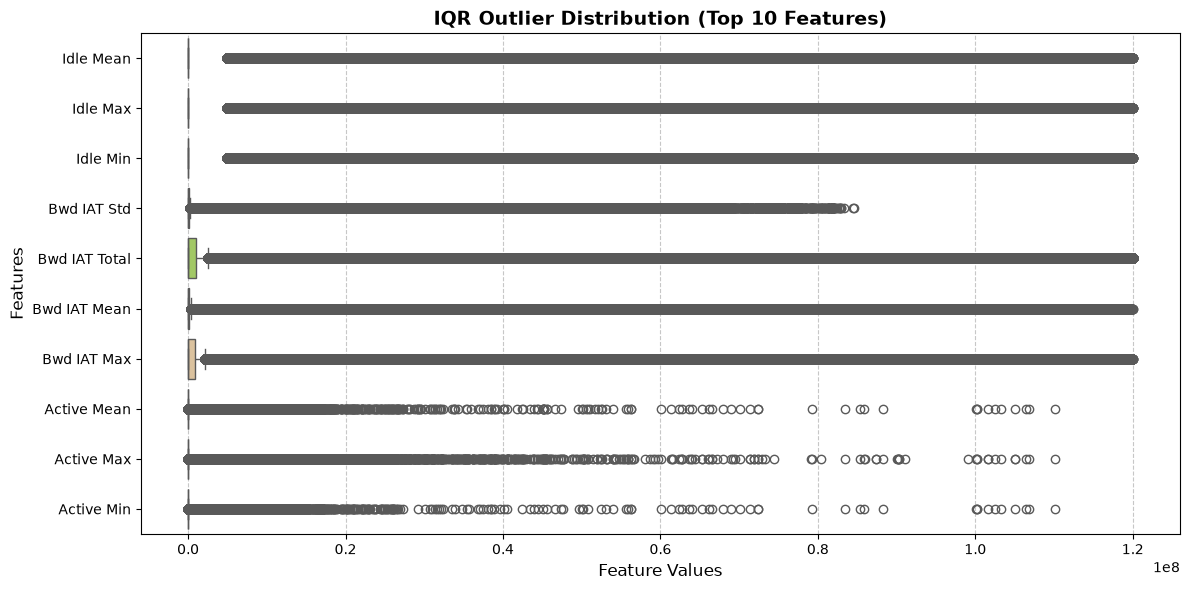

In [13]:
top_features = outliers_summary.head(10)["Feature"].to_list()


plot_data = data.select(top_features).to_pandas()


plt.figure(figsize=(12, 6))
sns.boxplot(data=plot_data, orient="h", palette="Set2")

plt.title("IQR Outlier Distribution (Top 10 Features)", fontsize=14, fontweight='bold')
plt.xlabel("Feature Values", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()



In [14]:
numeric_cols = data.select(cs.numeric().exclude("Src Port", "Dst Port")).columns


n_cols = 2
n_rows = (len(numeric_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 6 * n_rows))
axes = axes.flatten()
data_copy = data.clone()
data_copy = data_copy.with_columns(
    pl.when(cs.numeric().is_infinite())
    .then(None)
    .otherwise(cs.numeric())
    .name.keep()
)
data_copy = data_copy.with_columns(
    cs.float().fill_nan(None).name.keep()
)
data_copy = data_copy.drop_nulls()

for i, col_name in enumerate(numeric_cols):
    ax = axes[i]
    
    col_array = data_copy[col_name].to_numpy()
    
    
    if len(col_array) == 0:
        continue
        
    
    counts, breakpoints = np.histogram(col_array, bins=50)

    sort_indices = np.argsort(counts)[::-1]
    sorted_counts = counts[sort_indices]

    bin_starts = breakpoints[:-1]
        
    sorted_bin_starts = bin_starts[sort_indices]

    x_positions = np.arange(len(sorted_counts))
    

    ax.bar(
        x_positions, 
        sorted_counts, 
        color='#1b4965', 
        edgecolor='black', 
        linewidth=0.3,
        alpha=0.85
    )
    

    ax.set_yscale('log')
    ax.set_ylim(bottom=0.5)
    
    ax.set_title(col_name, fontsize=8, fontweight='bold')
    ax.set_xticks(x_positions)
    

    formatted_labels = [f"{val:.2g}" for val in sorted_bin_starts]
    ax.set_xticklabels(formatted_labels, rotation=90, fontsize=10)

    ax.tick_params(axis='y', which='major', labelsize=6)
    ax.grid(True, axis='y', linestyle=':', alpha=0.3)


for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])


plt.tight_layout()
plt.show()

### Outlier Analysis: Why We Keep Extreme Values

Upon analyzing the IQR results, several features appear to contain a massive number of outliers. However, visualizing the distributions via histograms and boxplots reveals that the data is heavily **zero-inflated** (the vast majority of values are exactly zero). Because the 25th and 75th percentiles are often both zero, the IQR mathematically flags *any* non-zero value as an outlier.

In the context of cybersecurity, we must handle extreme values differently than in standard datasets:
* **Outliers are Signatures:** A sudden, extreme spike in values (e.g., 500,000 packets per second) is often the exact mathematical signature of an active threat, such as a Denial of Service (DoS) attack.
* **Preserving the Signal:** Deleting these outliers would inadvertently delete the malicious behavior our NIDS is trying to learn. 

**Preprocessing Strategy:** 
We will not clip or drop outliers. Instead, we will preserve the integrity of the attack signatures by utilizing **tree-based models** (like Random Forest), which make split decisions and are inherently immune to extreme scale differences. And if we used distance based models, we will use a **RobustScaler** to handle the scale variance without distorting the extreme values.

## 1.5 Impossible Negatives

In [15]:
negatives_summary = (
    data.select((cs.numeric() < 0).sum())
    .unpivot(variable_name="Feature", value_name="Negative_Count")
    .filter(pl.col("Negative_Count") > 0)
    .sort("Negative_Count", descending=True)
)

print(negatives_summary)

shape: (5, 2)
┌────────────────┬────────────────┐
│ Feature        ┆ Negative_Count │
│ ---            ┆ ---            │
│ str            ┆ u32            │
╞════════════════╪════════════════╡
│ Flow IAT Min   ┆ 2922           │
│ Flow Duration  ┆ 31             │
│ Flow Packets/s ┆ 31             │
│ Flow IAT Mean  ┆ 31             │
│ Flow IAT Max   ┆ 31             │
└────────────────┴────────────────┘


Due to known timestamp parsing anomalies and packet synchronization bugs in the network capture tools used to generate the CICIDS2017 dataset, certain flow features occasionally record impossible negative values. 

Since time increments, packet lengths, and flow sizes cannot physically be negative, these instances represent corrupted extraction artifacts rather than genuine network behavior or attack signatures. To maintain the mathematical integrity of the training data, we will identify the affected features and drop the corrupted rows entirely.

# 2. Data Cleaning

In [16]:
data.columns

['Flow ID',
 'Src IP',
 'Src Port',
 'Dst IP',
 'Dst Port',
 'Protocol',
 'Timestamp',
 'Flow Duration',
 'Total Fwd Packet',
 'Total Bwd packets',
 'Total Length of Fwd Packet',
 'Total Length of Bwd Packet',
 'Fwd Packet Length Max',
 'Fwd Packet Length Min',
 'Fwd Packet Length Mean',
 'Fwd Packet Length Std',
 'Bwd Packet Length Max',
 'Bwd Packet Length Min',
 'Bwd Packet Length Mean',
 'Bwd Packet Length Std',
 'Flow Bytes/s',
 'Flow Packets/s',
 'Flow IAT Mean',
 'Flow IAT Std',
 'Flow IAT Max',
 'Flow IAT Min',
 'Fwd IAT Total',
 'Fwd IAT Mean',
 'Fwd IAT Std',
 'Fwd IAT Max',
 'Fwd IAT Min',
 'Bwd IAT Total',
 'Bwd IAT Mean',
 'Bwd IAT Std',
 'Bwd IAT Max',
 'Bwd IAT Min',
 'Fwd PSH Flags',
 'Bwd PSH Flags',
 'Fwd URG Flags',
 'Bwd URG Flags',
 'Fwd Header Length',
 'Bwd Header Length',
 'Fwd Packets/s',
 'Bwd Packets/s',
 'Packet Length Min',
 'Packet Length Max',
 'Packet Length Mean',
 'Packet Length Std',
 'Packet Length Variance',
 'FIN Flag Count',
 'SYN Flag Count',
 'R

## 2.1 Identifier Columns

In [17]:
data = data.drop(['Flow ID','Src IP','Src Port','Dst IP','Dst Port','Timestamp'])

In [18]:
data.shape

(2100814, 78)

## 2.2 Duplicates

In [19]:
data.is_duplicated().sum()

450353

Notice more duplicates appeared after dropping identifier columns

In [20]:
data = data.unique(keep="first", maintain_order=True)

In [21]:
data.is_duplicated().sum()

0

## 2.3 Handling missing and infinite values

In [22]:
# Converting infinite to null
data = data.with_columns(
    pl.when(cs.numeric().is_infinite())
    .then(None)
    .otherwise(cs.numeric())
    .name.keep()
)
# Converting nan to null
data = data.with_columns(
    cs.float().fill_nan(None).name.keep()
)

In [23]:
# Calculating Label counts before dropping
attack_counts = (
    data.group_by("Label")
    .len(name="Number of Occurrences")
    .rename({"Label": "Attack Type"})
)

# Dataframe with no missing values
data_no_na = data.drop_nulls()

# Calculating Label counts after dropping
occurrences_nonull = (
    data_no_na.group_by("Label")
    .len(name="Occurrences w/o Null Rows")
    .rename({"Label": "Attack Type"})
)

# Merging both dataframes and calculating the difference
attack_counts = (
    attack_counts.join(occurrences_nonull, on="Attack Type", how="left")
    .with_columns(
        # Fill with 0 in case a specific attack type was entirely wiped out by the drop
        pl.col("Occurrences w/o Null Rows").fill_null(0) 
    )
    .with_columns(
        (pl.col("Number of Occurrences") - pl.col("Occurrences w/o Null Rows")).alias("Abs Difference")
    )
    .with_columns(
        ((pl.col("Abs Difference") * 100) / pl.col("Number of Occurrences")).round(2).alias("Difference %")
    )
)


attack_counts

Attack Type,Number of Occurrences,Occurrences w/o Null Rows,Abs Difference,Difference %
str,u32,u32,u32,f64
"""Bot""",738,738,0,0.0
"""Web Attack - XSS - Attempted""",652,652,0,0.0
"""DoS Slowhttptest""",1731,1731,0,0.0
"""Heartbleed""",11,11,0,0.0
"""FTP-Patator - Attempted""",11,11,0,0.0
"""DoS GoldenEye - Attempted""",77,77,0,0.0
"""DoS GoldenEye""",7567,7567,0,0.0
"""FTP-Patator""",3973,3973,0,0.0
"""SSH-Patator - Attempted""",8,8,0,0.0


Looking at the numbers dropping missing and infinite values would have no effect on the data so we'll drop them

In [24]:
data = data.drop_nulls()

In [25]:
data.null_count().sum().unpivot(variable_name="Feature", value_name="Null Count")

Feature,Null Count
str,u32
"""Protocol""",0
"""Flow Duration""",0
"""Total Fwd Packet""",0
"""Total Bwd packets""",0
"""Total Length of Fwd Packet""",0
"""Total Length of Bwd Packet""",0
"""Fwd Packet Length Max""",0
"""Fwd Packet Length Min""",0
"""Fwd Packet Length Mean""",0


## 2.4 Impossible Negatives

In [26]:
data = data.filter(
    ~pl.any_horizontal(cs.numeric() < 0)
)

In [27]:
negatives_summary = (
    data.select((cs.numeric() < 0).sum())
    .unpivot(variable_name="Feature", value_name="Negative_Count")
    .filter(pl.col("Negative_Count") > 0)
    .sort("Negative_Count", descending=True)
)

print(negatives_summary)

shape: (0, 2)
┌─────────┬────────────────┐
│ Feature ┆ Negative_Count │
│ ---     ┆ ---            │
│ str     ┆ u32            │
╞═════════╪════════════════╡
└─────────┴────────────────┘


## 2.5 Handling Attempt Rows

As we explained earlier we're going to relabel attempted rows with benign

In [28]:
data["Label"].unique()

Label
str
"""Heartbleed"""
"""Infiltration"""
"""DoS Slowhttptest"""
"""Web Attack - XSS"""
"""Bot - Attempted"""
"""Infiltration - Attempted"""
"""DoS GoldenEye - Attempted"""
"""DoS GoldenEye"""
"""Web Attack - Brute Force - Att…"


In [29]:
data = data.with_columns(
    pl.when(pl.col("Label").str.ends_with("Attempted"))
    .then(pl.lit("BENIGN"))
    .otherwise(pl.col("Label"))
    .alias("Label")
)

In [30]:
data["Label"].unique()

Label
str
"""Web Attack - Brute Force"""
"""Web Attack - XSS"""
"""DoS GoldenEye"""
"""BENIGN"""
"""DoS slowloris"""
"""DDoS"""
"""FTP-Patator"""
"""Infiltration"""
"""SSH-Patator"""


## 2.6 Feature Selection

In [31]:
numeric_cols = data.select(cs.numeric()).columns
numeric_df = data.select(numeric_cols)


corr_matrix_pl = numeric_df.corr()


corr_matrix = corr_matrix_pl.to_pandas()
corr_matrix.index = numeric_cols  


threshold = 0.95
features_to_drop = set()


for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        col_A = corr_matrix.columns[i]
        col_B = corr_matrix.columns[j]
        
        
        if abs(corr_matrix.iloc[i, j]) > threshold:
            
            if col_A not in features_to_drop:
                features_to_drop.add(col_B)
                



print(f"\nTotal redundant features flagged for dropping: {len(features_to_drop)}")
data_reduced = data.drop(list(features_to_drop))

print(f"Original features: {len(data.columns)}")
print(f"Remaining features: {len(data_reduced.columns)}")


Total redundant features flagged for dropping: 25
Original features: 78
Remaining features: 53


# 3. Explaratory Data Analysis (EDA)

## 3.1 Data Overview

After all the cleaing we've done let's inspect our data again and see how it looks like

In [32]:
data_reduced.shape

(1711447, 53)

In [33]:
data_reduced.to_pandas().info()

<class 'pandas.DataFrame'>
RangeIndex: 1711447 entries, 0 to 1711446
Data columns (total 53 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   Protocol                    int32  
 1   Flow Duration               int32  
 2   Total Fwd Packet            int32  
 3   Total Length of Fwd Packet  float32
 4   Fwd Packet Length Max       float32
 5   Fwd Packet Length Min       float32
 6   Fwd Packet Length Mean      float32
 7   Fwd Packet Length Std       float32
 8   Bwd Packet Length Max       float32
 9   Bwd Packet Length Min       float32
 10  Bwd Packet Length Mean      float32
 11  Flow Bytes/s                float32
 12  Flow Packets/s              float32
 13  Flow IAT Mean               float32
 14  Flow IAT Std                float32
 15  Flow IAT Max                float32
 16  Flow IAT Min                float32
 17  Fwd IAT Mean                float32
 18  Fwd IAT Std                 float32
 19  Bwd IAT Std                 floa

## 3.1 Descriptive analysis

In [34]:
data_reduced.to_pandas().describe().T

,count,mean,std,min,25%,50%,75%,max
Protocol,1711447.0,1.140765e+01,5.507641e+00,0.000,6.000000,6.000000,1.700000e+01,1.700000e+01
Flow Duration,1711447.0,1.515500e+07,3.363373e+07,1.000,31024.000000,156429.000000,5.826880e+06,1.200000e+08
Total Fwd Packet,1711447.0,8.983222e+00,9.548350e+01,0.000,2.000000,4.000000,9.000000e+00,1.121410e+05
Total Length of Fwd Packet,1711447.0,6.778950e+02,1.148369e+04,0.000,59.000000,94.000000,4.300000e+02,1.287025e+07
Fwd Packet Length Max,1711447.0,2.528029e+02,5.332686e+02,0.000,36.000000,49.000000,3.530000e+02,2.482000e+04
Fwd Packet Length Min,1711447.0,2.214556e+01,3.638823e+01,0.000,0.000000,0.000000,4.200000e+01,1.472000e+03
Fwd Packet Length Mean,1711447.0,5.707154e+01,9.905761e+01,0.000,33.000000,43.000000,5.500000e+01,5.775500e+03
Fwd Packet Length Std,1711447.0,7.417735e+01,1.685639e+02,0.000,0.000000,0.000000,1.166398e+02,7.116542e+03
Bwd Packet Length Max,1711447.0,1.498104e+03,2.408459e+03,0.000,93.000000,168.000000,1.581000e+03,1.953000e+04
Bwd Packet Length Min,1711447.0,5.801861e+01,7.723999e+01,0.000,0.000000,0.000000,1.050000e+02,1.983000e+03


## 3.2 Analyzing Label 

C:\Users\Asus\AppData\Local\Temp\ipykernel_6888\2210591718.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


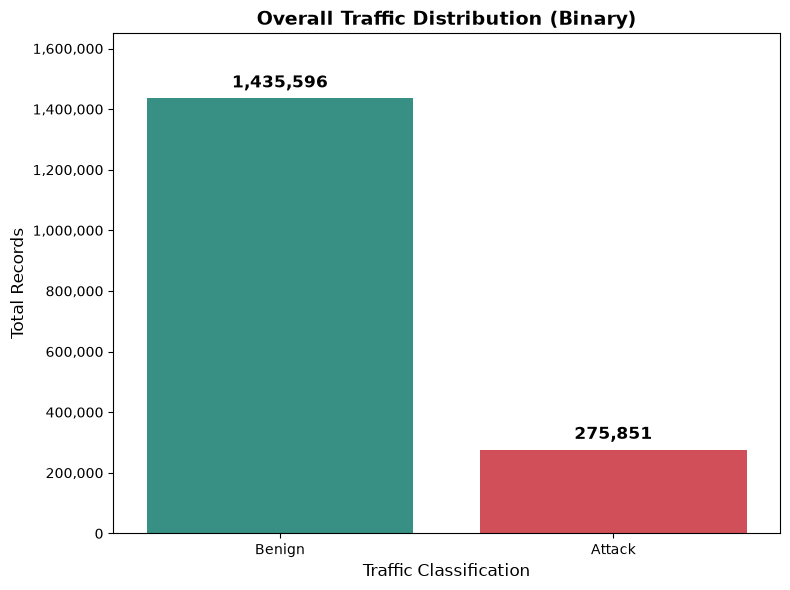

In [42]:
binary_counts = (
    data_reduced.with_columns(
        pl.when(pl.col("Label") == "BENIGN")
        .then(pl.lit("Benign"))
        .otherwise(pl.lit("Attack"))
        .alias("Binary_Label")
    )
    .group_by("Binary_Label")
    .len(name="Count")
    .sort("Count", descending=True)
    .to_pandas()
)


plt.figure(figsize=(8, 6))


ax = sns.barplot(
    data=binary_counts, 
    x="Binary_Label", 
    y="Count", 
    palette=["#2a9d8f", "#e63946"]
)


plt.title("Overall Traffic Distribution (Binary)", fontsize=14, fontweight='bold')
plt.xlabel("Traffic Classification", fontsize=12)
plt.ylabel("Total Records", fontsize=12)


ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))


for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', 
                fontsize=12, fontweight='bold',
                xytext=(0, 5), textcoords='offset points')


plt.ylim(0, binary_counts["Count"].max() * 1.15)

plt.tight_layout()
plt.show()

It's clear that the data is highly unbalanced 

C:\Users\Asus\AppData\Local\Temp\ipykernel_6888\463406327.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=label_counts, y="Label", x="Count", palette="magma")


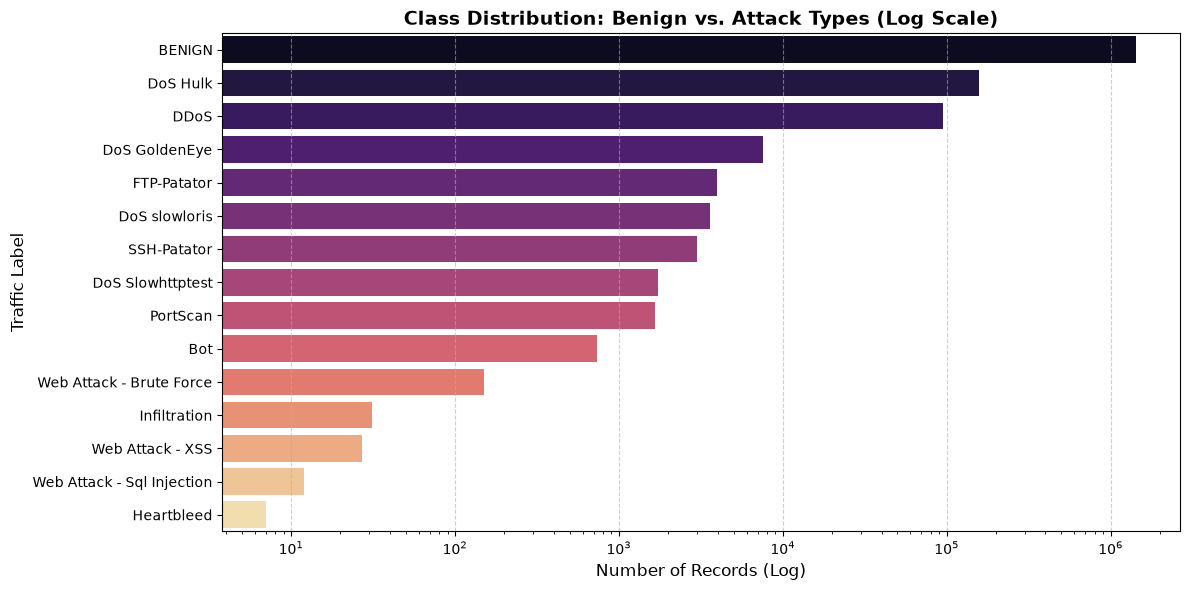

In [35]:
label_counts = (
    data_reduced.group_by("Label")
    .len(name="Count")
    .sort("Count", descending=True)
    .to_pandas()
)


plt.figure(figsize=(12, 6))
sns.barplot(data=label_counts, y="Label", x="Count", palette="magma")


plt.xscale("log")
plt.title("Class Distribution: Benign vs. Attack Types (Log Scale)", fontsize=14, fontweight='bold')
plt.xlabel("Number of Records (Log)", fontsize=12)
plt.ylabel("Traffic Label", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [36]:
data_reduced["Label"].value_counts()

Label,count
str,u32
"""Web Attack - Brute Force""",151
"""DDoS""",95098
"""DoS Slowhttptest""",1731
"""DoS slowloris""",3596
"""Bot""",738
"""PortScan""",1670
"""Heartbleed""",7
"""Infiltration""",31
"""DoS GoldenEye""",7562


## 3.3 Mutual Information

In [39]:
sample_df = data_reduced.sample(n=100000, seed=42).to_pandas()


X_sample = sample_df.drop(columns=["Label"])
y_sample = sample_df["Label"]


print("Calculating Mutual Information ...")
mi_scores = mutual_info_classif(X_sample, y_sample, random_state=42)


mi_series = pd.Series(mi_scores, index=X_sample.columns).sort_values(ascending=False)

print("\nTop 10 Features by Mutual Information:")
print(mi_series.head(10))

Calculating Mutual Information ...

Top 10 Features by Mutual Information:
Packet Length Variance        0.565150
Bwd Packet Length Max         0.535791
Bwd Init Win Bytes            0.528442
Fwd Packet Length Std         0.502476
Bwd Packet Length Mean        0.501284
Fwd Packet Length Max         0.495321
Total Length of Fwd Packet    0.468854
Fwd Packet Length Mean        0.418809
Flow Duration                 0.387947
Flow IAT Max                  0.383670
dtype: float64


C:\Users\Asus\AppData\Local\Temp\ipykernel_6888\3058921477.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Asus\AppData\Local\Temp\ipykernel_6888\3058921477.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Asus\AppData\Local\Temp\ipykernel_6888\3058921477.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Asus\AppData\Local\Temp\ipykernel_6888\3058921477.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and 

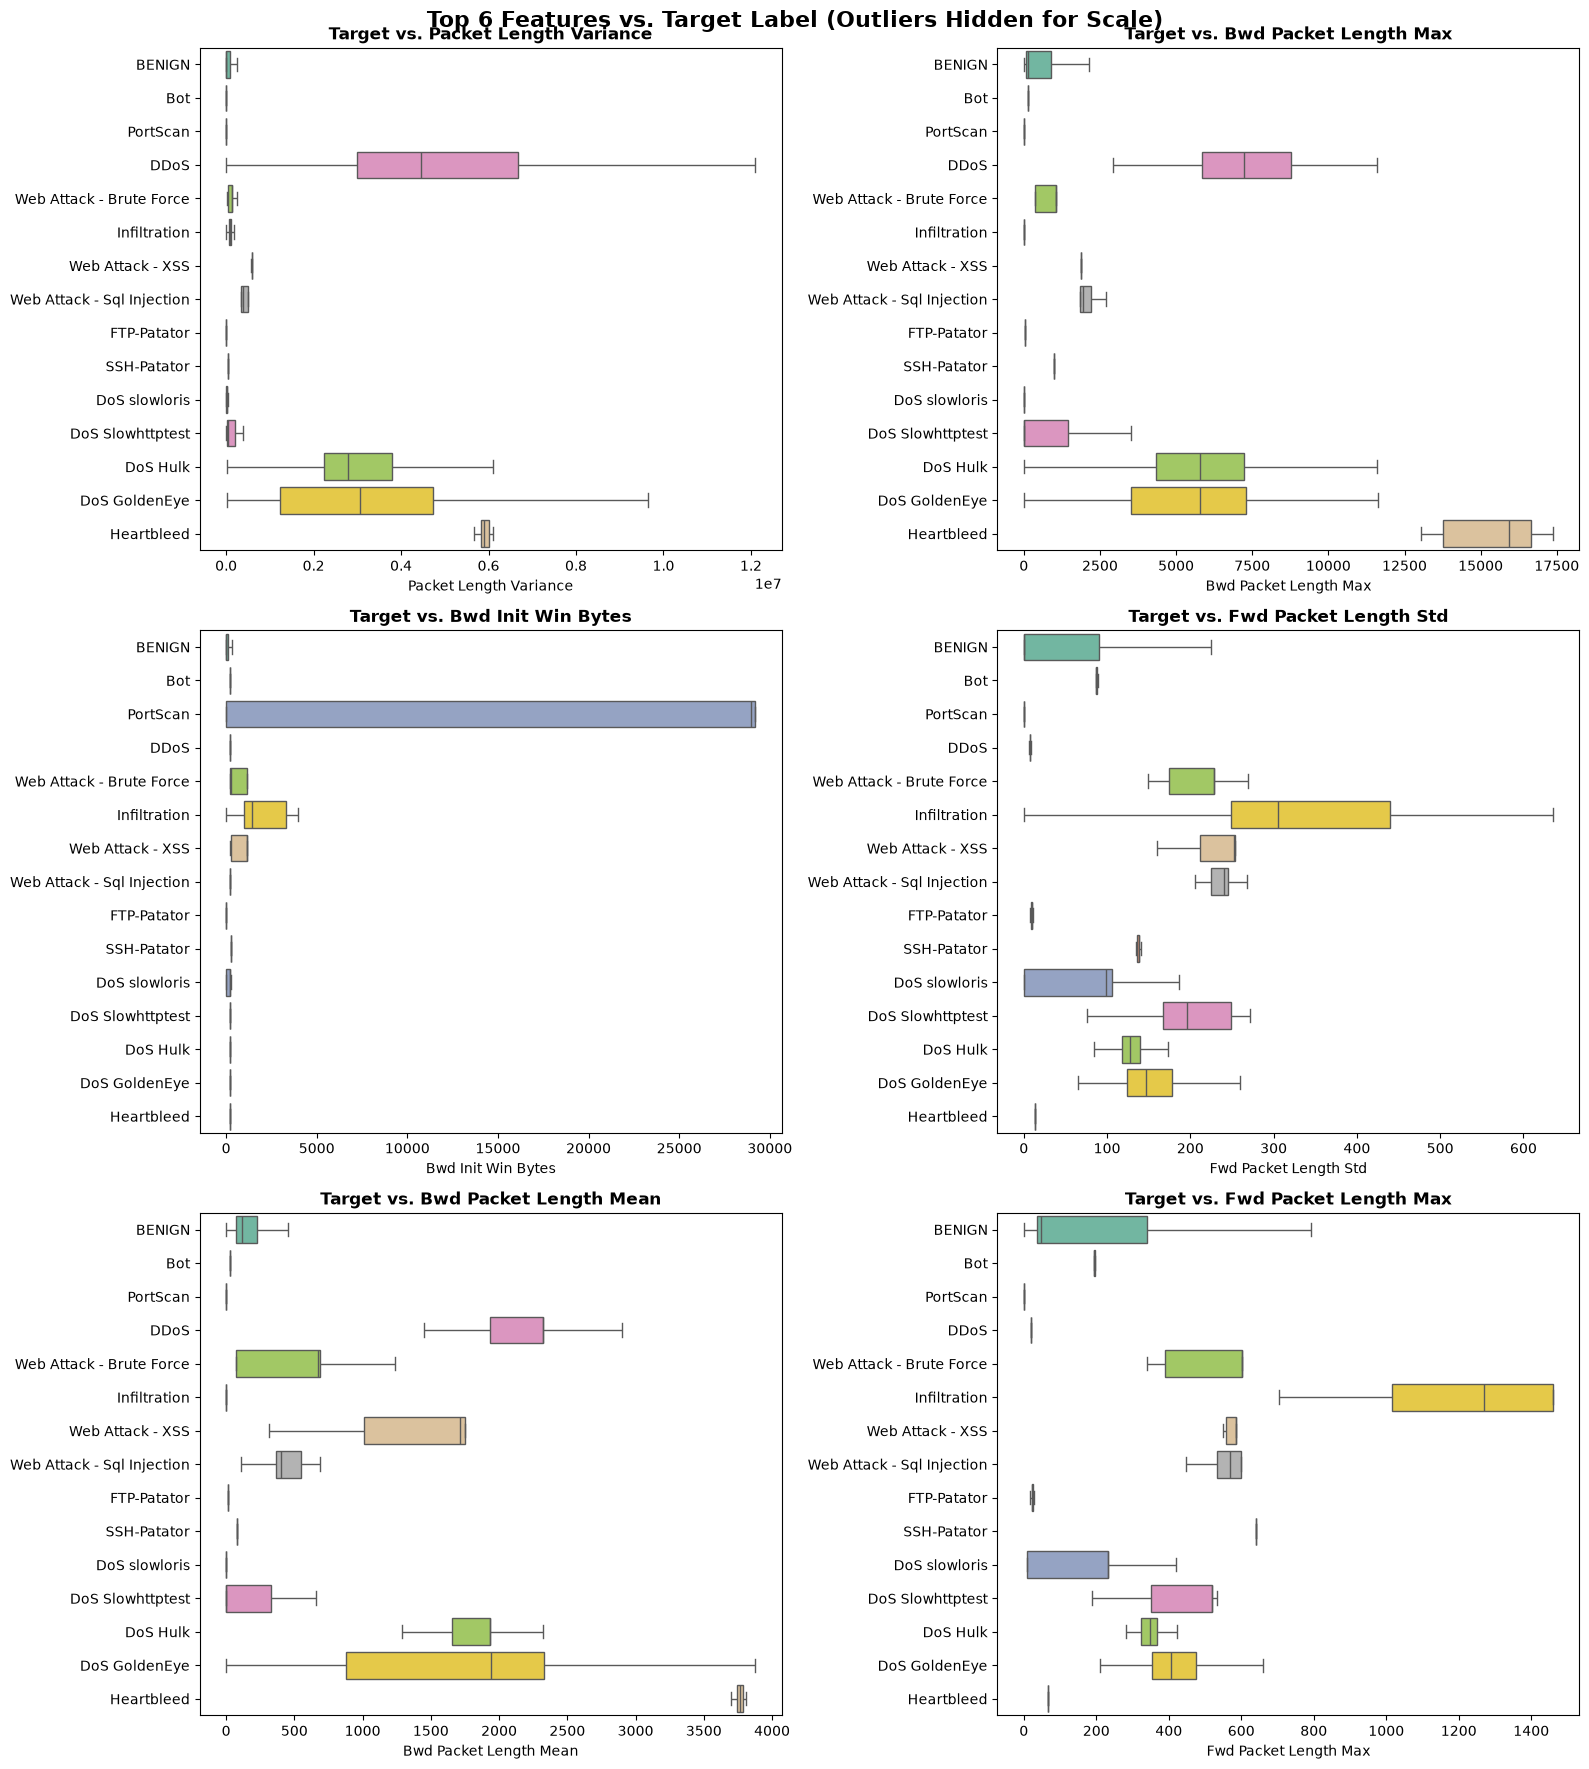

In [41]:
top_6_features = mi_series.head(6).index.tolist()


plot_cols = top_6_features + ["Label"]
plot_df = data_reduced.select(plot_cols).to_pandas()


fig, axes = plt.subplots(3, 2, figsize=(16, 18))
axes = axes.flatten()

for i, feature in enumerate(top_6_features):
    ax = axes[i]
    

    sns.boxplot(
        data=plot_df, 
        y="Label", 
        x=feature, 
        ax=ax, 
        palette="Set2",
        showfliers=False 
    )
    
    ax.set_title(f"Target vs. {feature}", fontweight='bold')
    ax.set_xlabel(feature)
    ax.set_ylabel("")

plt.suptitle("Top 6 Features vs. Target Label (Outliers Hidden for Scale)", 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# 4. Baseline Models

## 4.1 Binary classification (BENIGN & Attack only)

In [47]:
data_ml = (
    data_reduced
    .with_columns(pl.col("Protocol").cast(pl.String))
    .to_dummies("Protocol")
)

data_ml = data_reduced.with_columns(
    pl.when(pl.col("Label") == "BENIGN")
    .then(0)
    .otherwise(1)
    .alias("Target")
)


X = data_ml.drop(["Label", "Target"]).to_numpy()
y = data_ml.select("Target").to_numpy().ravel()


print("Splitting data...")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]:,} rows")
print(f"Testing set: {X_test.shape[0]:,} rows")

Splitting data...
Training set: 1,369,157 rows
Testing set: 342,290 rows


In [48]:
rf_clf = RandomForestClassifier(
    n_estimators=100, 
    class_weight="balanced", 
    random_state=42, 
    n_jobs=-1
)


print("Training Random Forest (This may take a few minutes)...")
rf_clf.fit(X_train, y_train)

Training Random Forest (This may take a few minutes)...


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

Generating predictions...

--- Classification Report (train) ---
              precision    recall  f1-score   support

  Benign (0)     1.0000    0.9999    1.0000   1148476
  Attack (1)     0.9996    1.0000    0.9998    220681

    accuracy                         0.9999   1369157
   macro avg     0.9998    1.0000    0.9999   1369157
weighted avg     0.9999    0.9999    0.9999   1369157



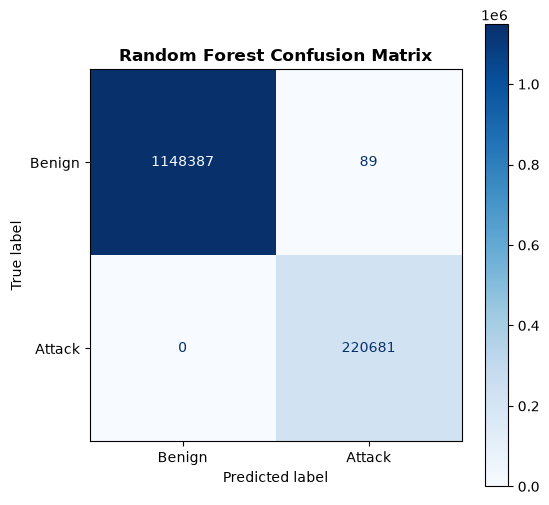

In [49]:
print("Generating predictions...")
y_pred = rf_clf.predict(X_train)


print("\n--- Classification Report (train) ---")
print(classification_report(y_train, y_pred, target_names=["Benign (0)", "Attack (1)"], digits=4))


cm = confusion_matrix(y_train, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Benign", "Attack"])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap="Blues", ax=ax, values_format="d")
plt.title("Random Forest Confusion Matrix", fontweight="bold")
plt.show()

Generating predictions...

--- Classification Report(test) ---
              precision    recall  f1-score   support

  Benign (0)     0.9999    0.9999    0.9999    287120
  Attack (1)     0.9997    0.9996    0.9996     55170

    accuracy                         0.9999    342290
   macro avg     0.9998    0.9998    0.9998    342290
weighted avg     0.9999    0.9999    0.9999    342290



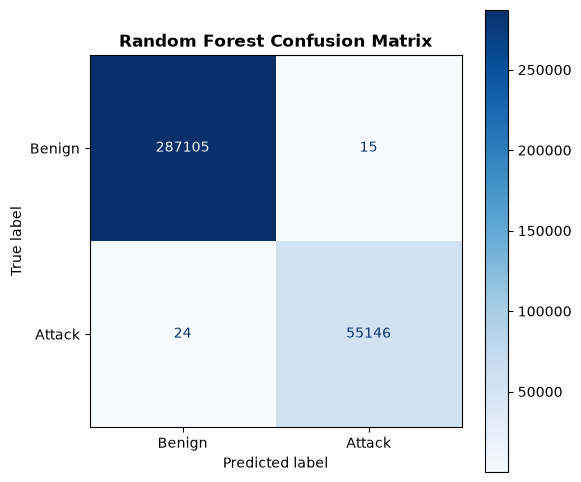

In [50]:
print("Generating predictions...")
y_pred = rf_clf.predict(X_test)


print("\n--- Classification Report(test) ---")
print(classification_report(y_test, y_pred, target_names=["Benign (0)", "Attack (1)"], digits=4))


cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Benign", "Attack"])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap="Blues", ax=ax, values_format="d")
plt.title("Random Forest Confusion Matrix", fontweight="bold")
plt.show()

In [51]:
def plot_multiclass_matrix(y_true, y_pred, labels_in_data, display_names, title):
    
    cm = confusion_matrix(y_true, y_pred, labels=labels_in_data)
    
    
    fig, ax = plt.subplots(figsize=(14, 12))
    
    
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=display_names)
    
    
    disp.plot(cmap="Blues", ax=ax, values_format="d", xticks_rotation="vertical")
    
    plt.title(title, fontweight="bold", fontsize=16)
    
    
    plt.tight_layout()
    plt.show()

## 4.2 Standard Multiclass

In [52]:
data_multi = (
    data_reduced
    .with_columns(pl.col("Protocol").cast(pl.String))
    .to_dummies("Protocol")
)


X_multi = data_multi.drop("Label").to_numpy()
y_multi = data_multi.select("Label").to_numpy().ravel()


X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y_multi, test_size=0.20, random_state=42, stratify=y_multi
)


print("Training Standard Multiclass Random Forest...")
rf_multi = RandomForestClassifier(
    n_estimators=100, 
    class_weight="balanced", 
    random_state=42, 
    n_jobs=-1
)
rf_multi.fit(X_train_m, y_train_m)


Training Standard Multiclass Random Forest...


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [53]:
y_pred_m = rf_multi.predict(X_train_m)
print("\n--- Standard Multiclass Report (train) ---")
print(classification_report(y_train_m, y_pred_m, digits=4))


--- Standard Multiclass Report (train) ---
                            precision    recall  f1-score   support

                    BENIGN     1.0000    0.9999    0.9999   1148476
                       Bot     0.9966    1.0000    0.9983       590
                      DDoS     1.0000    1.0000    1.0000     76078
             DoS GoldenEye     0.9998    1.0000    0.9999      6049
                  DoS Hulk     1.0000    1.0000    1.0000    126625
          DoS Slowhttptest     0.9986    1.0000    0.9993      1385
             DoS slowloris     0.9986    1.0000    0.9993      2877
               FTP-Patator     1.0000    1.0000    1.0000      3175
                Heartbleed     1.0000    1.0000    1.0000         6
              Infiltration     1.0000    1.0000    1.0000        25
                  PortScan     0.9070    1.0000    0.9512      1336
               SSH-Patator     1.0000    1.0000    1.0000      2382
  Web Attack - Brute Force     0.9918    1.0000    0.9959       121
Web

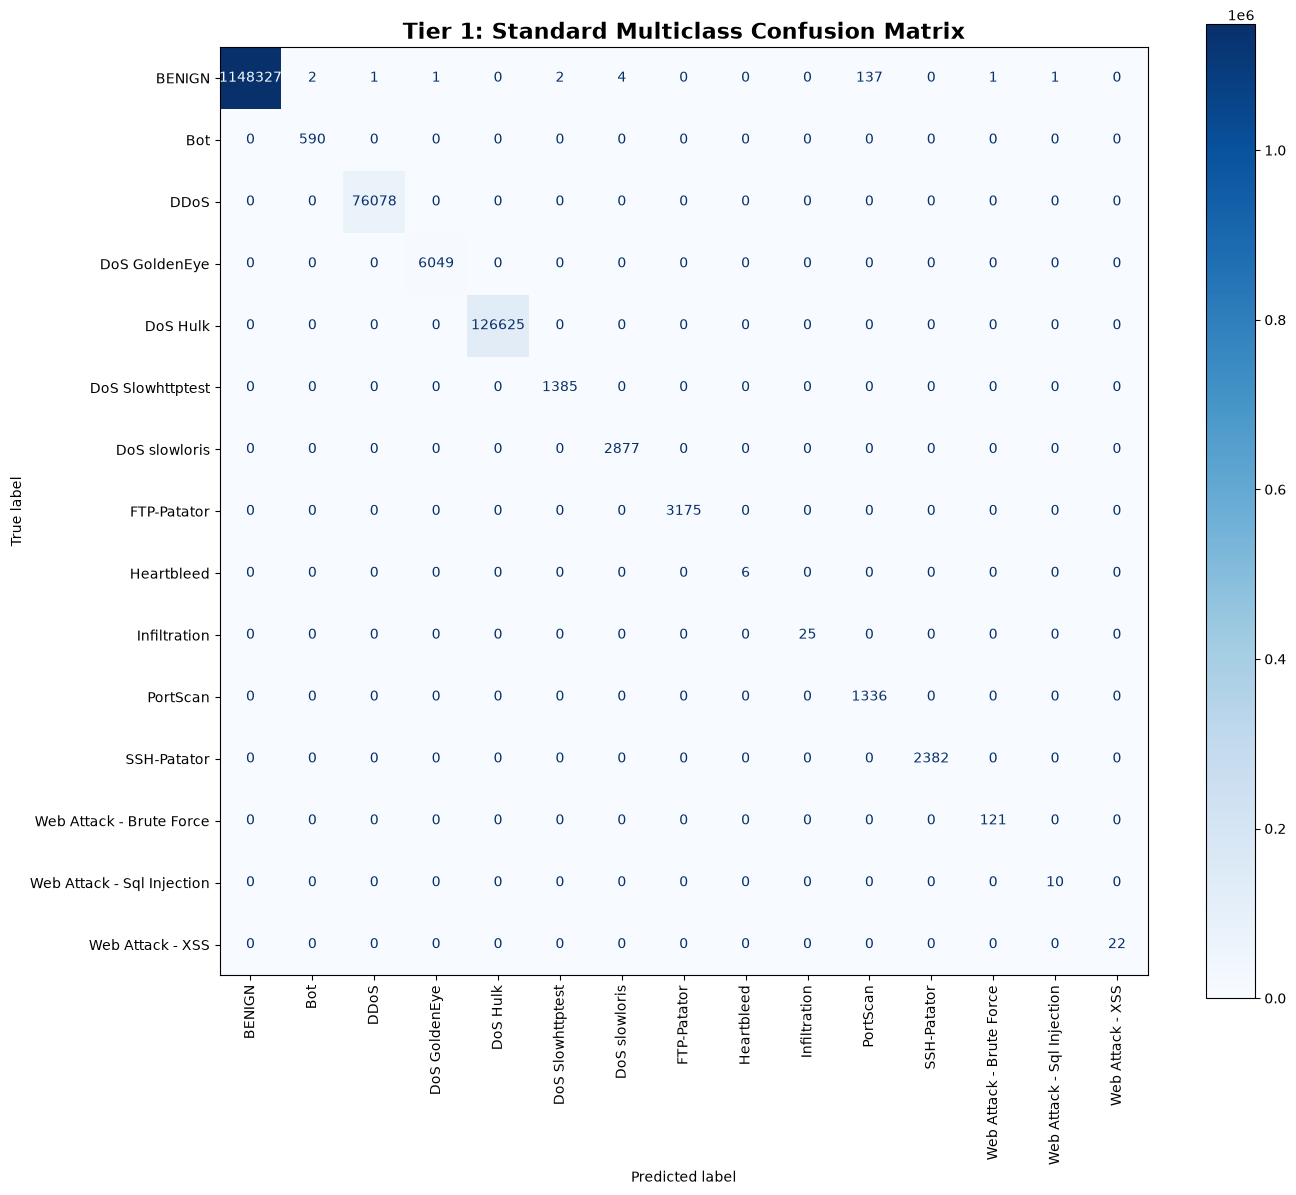

In [54]:
plot_multiclass_matrix(
    y_train_m, 
    y_pred_m, 
    labels_in_data=rf_multi.classes_, 
    display_names=rf_multi.classes_,
    title="Tier 1: Standard Multiclass Confusion Matrix"
)

In [55]:
y_pred_m = rf_multi.predict(X_test_m)
print("\n--- Standard Multiclass Report (test) ---")
print(classification_report(y_test_m, y_pred_m, digits=4))


--- Standard Multiclass Report (test) ---
                            precision    recall  f1-score   support

                    BENIGN     1.0000    0.9999    0.9999    287120
                       Bot     1.0000    1.0000    1.0000       148
                      DDoS     1.0000    1.0000    1.0000     19020
             DoS GoldenEye     1.0000    0.9993    0.9997      1513
                  DoS Hulk     1.0000    1.0000    1.0000     31656
          DoS Slowhttptest     1.0000    0.9942    0.9971       346
             DoS slowloris     1.0000    0.9986    0.9993       719
               FTP-Patator     1.0000    1.0000    1.0000       794
                Heartbleed     1.0000    1.0000    1.0000         1
              Infiltration     1.0000    0.8333    0.9091         6
                  PortScan     0.9352    0.9940    0.9637       334
               SSH-Patator     1.0000    0.9983    0.9992       596
  Web Attack - Brute Force     0.9655    0.9333    0.9492        30
Web 

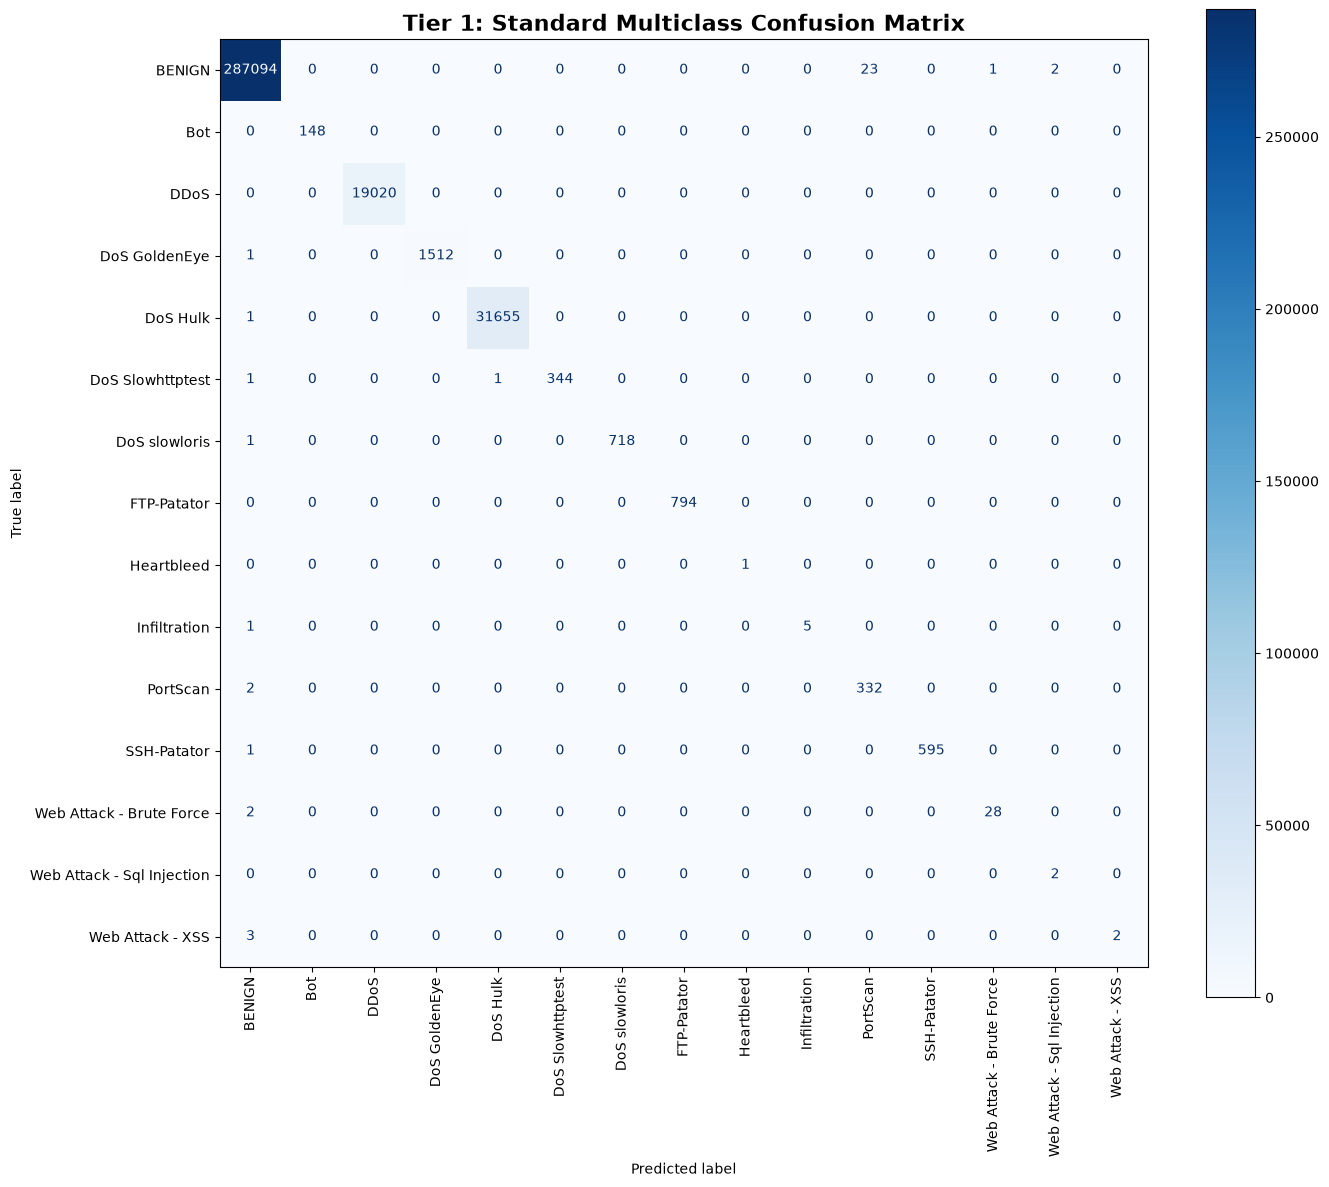

In [56]:
plot_multiclass_matrix(
    y_test_m, 
    y_pred_m, 
    labels_in_data=rf_multi.classes_, 
    display_names=rf_multi.classes_,
    title="Tier 1: Standard Multiclass Confusion Matrix"
)

## 4.3 Specialist Model

In [57]:
data_attacks_only = data_multi.filter(pl.col("Label") != "BENIGN")


X_atk = data_attacks_only.drop("Label").to_numpy()
y_atk = data_attacks_only.select("Label").to_numpy().ravel()


print(f"Total Attack Records for Tier 2 Model: {len(data_attacks_only):,}")
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_atk, y_atk, test_size=0.20, random_state=42, stratify=y_atk
)


print("Training Tier 2 Specialist Random Forest...")
rf_specialist = RandomForestClassifier(
    n_estimators=100, 
    class_weight="balanced", 
    random_state=42, 
    n_jobs=-1
)
rf_specialist.fit(X_train_a, y_train_a)


Total Attack Records for Tier 2 Model: 275,851
Training Tier 2 Specialist Random Forest...


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [58]:
y_pred_a = rf_specialist.predict(X_train_a)
print("\n--- Tier 2 Specialist Report on train (Attacks Only) ---")
print(classification_report(y_train_a, y_pred_a, digits=4))


--- Tier 2 Specialist Report on train (Attacks Only) ---
                            precision    recall  f1-score   support

                       Bot     1.0000    1.0000    1.0000       590
                      DDoS     1.0000    1.0000    1.0000     76078
             DoS GoldenEye     1.0000    1.0000    1.0000      6049
                  DoS Hulk     1.0000    0.9999    1.0000    126624
          DoS Slowhttptest     0.9950    1.0000    0.9975      1385
             DoS slowloris     1.0000    1.0000    1.0000      2877
               FTP-Patator     1.0000    1.0000    1.0000      3175
                Heartbleed     1.0000    1.0000    1.0000         6
              Infiltration     1.0000    1.0000    1.0000        25
                  PortScan     1.0000    1.0000    1.0000      1336
               SSH-Patator     1.0000    1.0000    1.0000      2382
  Web Attack - Brute Force     0.9918    1.0000    0.9959       121
Web Attack - Sql Injection     1.0000    1.0000    1.0000

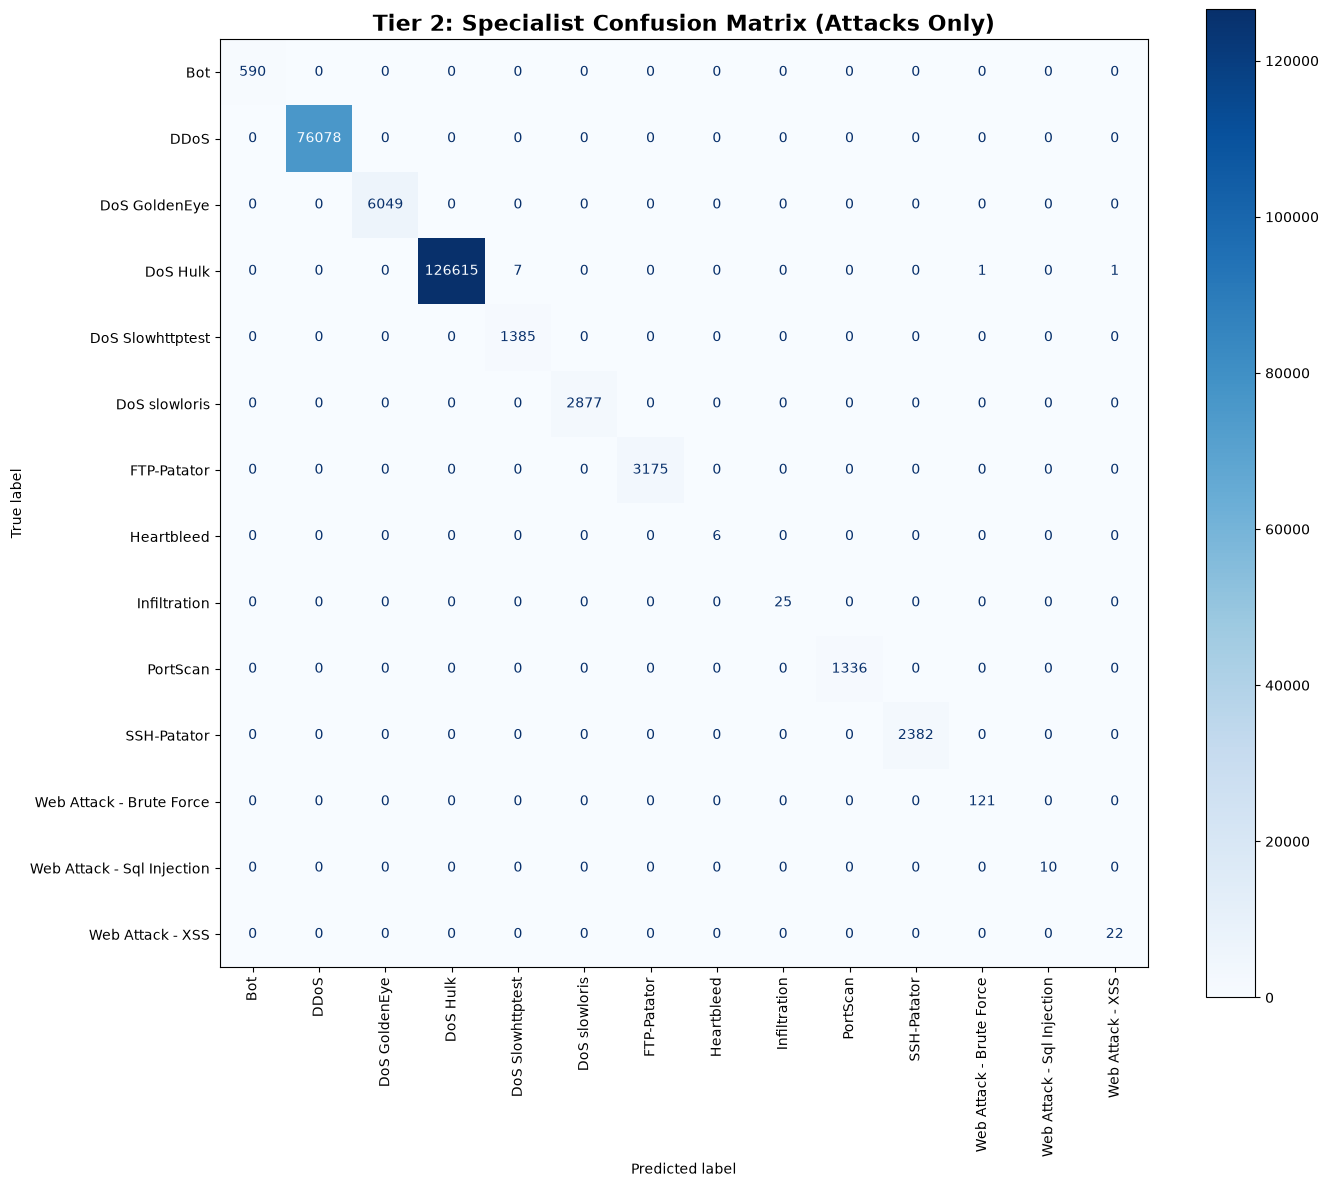

In [59]:
plot_multiclass_matrix(
    y_train_a, 
    y_pred_a, 
    labels_in_data=rf_specialist.classes_, 
    display_names=rf_specialist.classes_,
    title="Tier 2: Specialist Confusion Matrix (Attacks Only)"
)

In [60]:
y_pred_a = rf_specialist.predict(X_test_a)
print("\n--- Tier 2 Specialist Report on test (Attacks Only) ---")
print(classification_report(y_test_a, y_pred_a, digits=4))


--- Tier 2 Specialist Report on test (Attacks Only) ---
                            precision    recall  f1-score   support

                       Bot     1.0000    1.0000    1.0000       148
                      DDoS     1.0000    1.0000    1.0000     19020
             DoS GoldenEye     0.9974    1.0000    0.9987      1513
                  DoS Hulk     1.0000    0.9999    1.0000     31657
          DoS Slowhttptest     0.9942    0.9913    0.9928       346
             DoS slowloris     0.9986    0.9986    0.9986       719
               FTP-Patator     0.9987    1.0000    0.9994       794
                Heartbleed     1.0000    1.0000    1.0000         1
              Infiltration     1.0000    1.0000    1.0000         6
                  PortScan     1.0000    0.9940    0.9970       334
               SSH-Patator     1.0000    0.9950    0.9975       596
  Web Attack - Brute Force     1.0000    0.9667    0.9831        30
Web Attack - Sql Injection     1.0000    1.0000    1.0000 

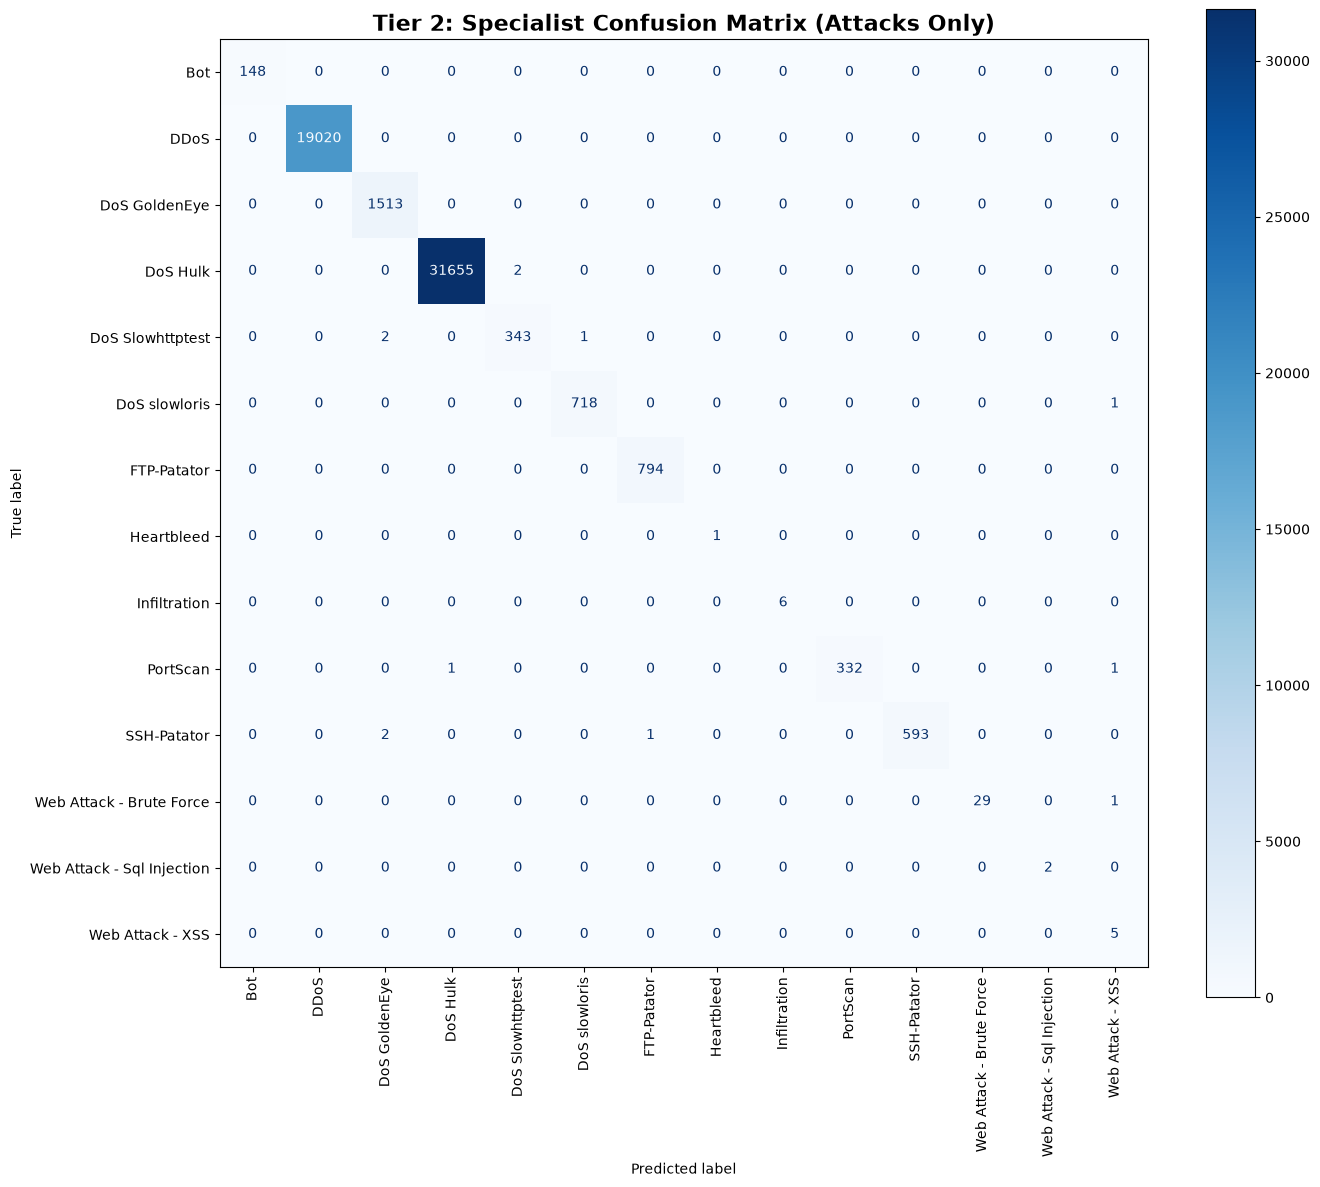

In [61]:
plot_multiclass_matrix(
    y_test_a, 
    y_pred_a, 
    labels_in_data=rf_specialist.classes_, 
    display_names=rf_specialist.classes_,
    title="Tier 2: Specialist Confusion Matrix (Attacks Only)"
)

In [65]:
joblib.dump(rf_clf, '../models/binary_model.pkl')
joblib.dump(rf_multi, '../models/standard_multi_model.pkl')
joblib.dump(rf_specialist, '../models/specialist_model.pkl')
joblib.dump(X_train_m.columns.tolist() if hasattr(X_train_m, 'columns') else data_multi.drop("Label").columns, '../models/feature_names.pkl')

['../models/feature_names.pkl']